<a id="introduction"></a>
# User Behavior and A/A/B Test Analysis

## Introduction

This project analyzes user behavior in a food retail mobile application. The main objective is to understand how users interact with the app, identify where users are lost in the sales funnel, and evaluate the results of an A/A/B experiment.

The analysis is divided into two main parts. First, the user journey through the application will be examined by analyzing the event funnel and calculating conversion rates between its main stages. This will help identify where the largest user drop-offs occur and how many users ultimately reach the payment stage.

Second, the results of an A/A/B experiment will be analyzed. Users were divided into two control groups (246 and 247), which used the original fonts, and one test group (248), which used new fonts. Statistical hypothesis tests will be performed to determine whether the change in fonts had a significant effect on user behavior.

Before these analyses, the dataset will be cleaned and explored to ensure that the available data is suitable and reliable for the study.

## Table of Contents

1. [Introduction](#introduction)
2. [Data Overview and Preparation](#data-overview-and-preparation)
   - [2.1 Data Overview](#21-data-overview)
   - [2.2 Column Renaming](#22-column-renaming)
   - [2.3 Missing Values and Duplicates](#23-missing-values-and-duplicates)
   - [2.4 Data Types](#24-data-types)
   - [2.5 Date and Time Preparation](#25-date-and-time-preparation)
3. [Exploratory Data Analysis](#exploratory-data-analysis)
   - [3.1 Number of Events and Users](#31-number-of-events-and-users)
   - [3.2 Average Number of Events per User](#32-average-number-of-events-per-user)
   - [3.3 Analysis of the Time Period](#33-analysis-of-the-time-period)
   - [3.4 Filtering Incomplete Data](#34-filtering-incomplete-data)
   - [3.5 Experimental Groups](#35-experimental-groups)
4. [Event Funnel Analysis](#event-funnel-analysis)
   - [4.1 Event Frequency](#41-event-frequency)
   - [4.2 Users per Event](#42-users-per-event)
   - [4.3 Event Sequence](#43-event-sequence)
   - [4.4 Funnel Conversion Rates](#44-funnel-conversion-rates)
   - [4.5 User Drop-Off](#45-user-drop-off)
   - [4.6 Overall Funnel Conversion](#46-overall-funnel-conversion)
5. [A/A/B Experiment Analysis](#aab-experiment-analysis)
   - [5.1 Users per Experimental Group](#51-users-per-experimental-group)
   - [5.2 A/A Test: Groups 246 and 247](#52-aa-test-groups-246-and-247)
   - [5.3 Statistical Tests by Event](#53-statistical-tests-by-event)
   - [5.4 Comparison with Experimental Group 248](#54-comparison-with-experimental-group-248)
   - [5.5 Combined Control Groups vs. Experimental Group](#55-combined-control-groups-vs-experimental-group)
   - [5.6 Significance Level and Multiple Testing](#56-significance-level-and-multiple-testing)
6. [Overall Conclusion](#overall-conclusion)

<a id="data-overview-and-preparation"></a>
## 2. Data Overview and Preparation

<a id="21-data-overview"></a>
### 2.1 Data Overview

First, we will load the required libraries and the dataset. Then, we will examine the first rows and general information about the data to understand its structure.

In [1]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as st

In [2]:
# Load the tab-separated event log from the local data folder
logs = pd.read_csv('data/logs_exp_us.csv', sep='\t')

# Display the first five rows
logs.head()

Out[2]: 
                 EventName         DeviceIDHash  EventTimestamp  ExpId
0         MainScreenAppear  4575588528974610257      1564029816    246
1         MainScreenAppear  7416695313311560658      1564053102    246
2  PaymentScreenSuccessful  3518123091307005509      1564054127    248
3         CartScreenAppear  3518123091307005509      1564054127    248
4  PaymentScreenSuccessful  6217807653094995999      1564055322    248


In [3]:
# Display general information about the dataset
logs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244126 entries, 0 to 244125
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   EventName       244126 non-null  object
 1   DeviceIDHash    244126 non-null  int64 
 2   EventTimestamp  244126 non-null  int64 
 3   ExpId           244126 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 7.5+ MB


<a id="22-column-renaming"></a>
### 2.2 Column Renaming

The column names will be renamed using snake_case to make them clearer and easier to work with throughout the analysis.

In [4]:
# Rename columns using snake_case
logs = logs.rename(columns={
    'EventName' : 'event_name',
    'DeviceIDHash' : 'user_id',
    'EventTimestamp' : 'event_timestamp',
    'ExpId': 'experiment_id'
})

# Chech the new column names
logs.columns

Out[4]: Index(['event_name', 'user_id', 'event_timestamp', 'experiment_id'], dtype='object')


<a id="23-missing-values-and-duplicates"></a>
### 2.3 Missing Values and Duplicates

The dataset will be checked for missing values and duplicated rows to identify potential data quality issues before the analysis.

In [5]:
# Check for missing values
logs.isna().sum()

Out[5]: 
event_name         0
user_id            0
event_timestamp    0
experiment_id      0
dtype: int64


In [6]:
# Check for duplicated rows
logs.duplicated().sum()

Out[6]: np.int64(413)


In [7]:
# Display duplicated rows
logs[logs.duplicated(keep=False)].sort_values(
    by=['user_id', 'event_timestamp']
).head(20)

Out[7]: 
                     event_name  ...  experiment_id
130557         MainScreenAppear  ...            248
130558         MainScreenAppear  ...            248
130994       OffersScreenAppear  ...            248
130995       OffersScreenAppear  ...            248
104106         CartScreenAppear  ...            248
104108         CartScreenAppear  ...            248
159301  PaymentScreenSuccessful  ...            248
159302  PaymentScreenSuccessful  ...            248
176812  PaymentScreenSuccessful  ...            246
176813  PaymentScreenSuccessful  ...            246
189894         MainScreenAppear  ...            246
189896         MainScreenAppear  ...            246
155463         MainScreenAppear  ...            247
155464         MainScreenAppear  ...            247
110478         MainScreenAppear  ...            246
110479         MainScreenAppear  ...            246
17036          CartScreenAppear  ...            246
17037          CartScreenAppear  ...            246
234

In [8]:
# Remove duplicated rows
logs = logs.drop_duplicates().reset_index(drop=True)

# Check that duplicates were removed
logs.duplicated().sum()

Out[8]: np.int64(0)


**Findings:**

No missing values were found in the dataset. However, 413 fully duplicated rows were identified. Since these rows contained identical information for the same user, event, timestamp, and experimental group, they were removed to avoid double-counting events in the analysis.

<a id="24-data-types"></a>
### 2.4 Data Types

The data types will be reviewed to determine whether they are appropriate for the analysis.

In [9]:
# Check data types
logs.dtypes

Out[9]: 
event_name         object
user_id             int64
event_timestamp     int64
experiment_id       int64
dtype: object


**Findings:**

The data types are generally appropriate for the analysis. However, `event_timestamp` is stored as an integer even though it represents the date and time of each event. This column will be converted to datetime format in the next step.

<a id="25-date-and-time-preparation"></a>
### 2.5 Date and Time Preparation

The `event_timestamp` column is stored as a Unix timestamp. It will be converted to datetime format, and a separate column containing only the event date will be created.

In [10]:
# Convert Unix timestamp to datetime
logs['event_datetime'] = pd.to_datetime(
    logs['event_timestamp'],
    unit='s'
)

# Create a separate date column
logs['event_date'] = logs['event_datetime'].dt.date

logs.head()

Out[10]: 
                event_name              user_id  ...      event_datetime  event_date
0         MainScreenAppear  4575588528974610257  ... 2019-07-25 04:43:36  2019-07-25
1         MainScreenAppear  7416695313311560658  ... 2019-07-25 11:11:42  2019-07-25
2  PaymentScreenSuccessful  3518123091307005509  ... 2019-07-25 11:28:47  2019-07-25
3         CartScreenAppear  3518123091307005509  ... 2019-07-25 11:28:47  2019-07-25
4  PaymentScreenSuccessful  6217807653094995999  ... 2019-07-25 11:48:42  2019-07-25

[5 rows x 6 columns]


**Findings:**

The Unix timestamps were successfully converted to datetime format. A separate `event_date` column was also created to facilitate date-based analysis. The dataset is now prepared for further analysis.

<a id="exploratory-data-analysis"></a>
## 3. Exploratory Data Analysis

<a id="31-number-of-events-and-users"></a>
### 3.1 Number of Events and Users

First, we will calculate the total number of events and the number of unique users in the dataset.

In [11]:
# Calculate the total number of events
events_number = len(logs['event_name'])

# Display the result
print('Number of events:', events_number)

Number of events: 243713


In [12]:
# Calculate the number of unique users
users_number = logs['user_id'].nunique()

# Display the result
print('Number of users:', users_number)

Number of users: 7551


<a id="32-average-number-of-events-per-user"></a>
### 3.2 Average Number of Events per User

Next, we will calculate the average number of events generated per user.

In [13]:
# Calculate tha average number of events per user
avg_events_per_user = events_number / users_number

# Display the result
print('Average number of events per user:', avg_events_per_user )

Average number of events per user: 32.27559263673685


<a id="33-analysis-of-the-time-period"></a>
### 3.3 Analysis of the Time Period

The minimum and maximum event dates will be examined to determine the time period initially covered by the dataset.

In [14]:
# Find the minimum and maximum event dates
min_date = logs['event_datetime'].min()
max_date = logs['event_datetime'].max()

# Display the results
print('Minimum date:', min_date)
print('Maximum date:', max_date)

Minimum date: 2019-07-25 04:43:36
Maximum date: 2019-08-07 21:15:17


In [15]:
# Count the number of events per day
events_per_day = logs.groupby('event_date').size()

# Display the result
events_per_day

Out[15]: 
event_date
2019-07-25        9
2019-07-26       31
2019-07-27       55
2019-07-28      105
2019-07-29      184
2019-07-30      412
2019-07-31     2030
2019-08-01    36141
2019-08-02    35554
2019-08-03    33282
2019-08-04    32968
2019-08-05    36058
2019-08-06    35788
2019-08-07    31096
dtype: int64


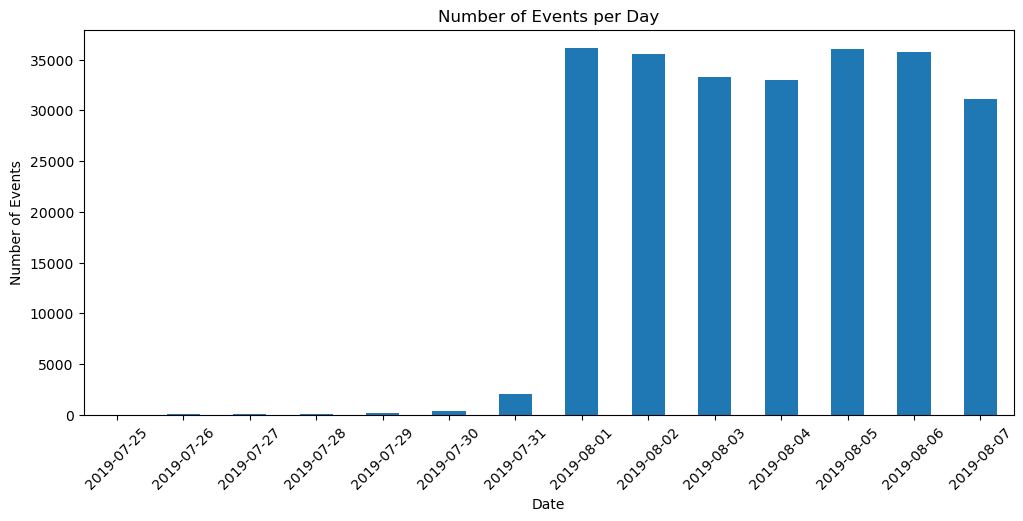

In [16]:
# Plot the number of events per day
events_per_day.plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Number of Events per Day')
plt.xlabel('Date')
plt.ylabel('Number of Events')
plt.xticks(rotation=45)
plt.show()

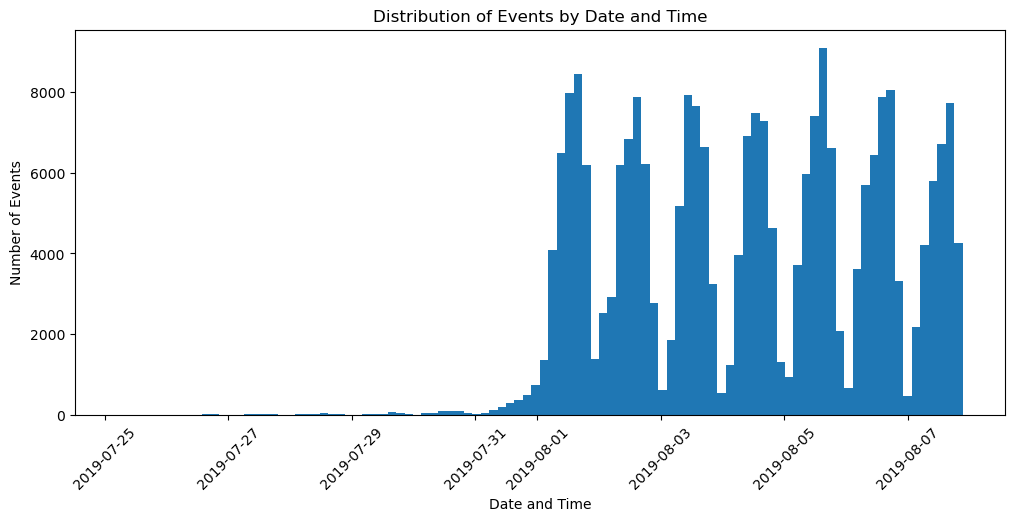

In [17]:
# Plot the distribution of events by date and time
plt.figure(figsize=(12, 5))

plt.hist(
    logs['event_datetime'],
    bins=100
)

plt.title('Distribution of Events by Date and Time')
plt.xlabel('Date and Time')
plt.ylabel('Number of Events')
plt.xticks(rotation=45)
plt.show()

**Findings:**

The dataset initially covers the period from July 25, 2019 to August 7, 2019. However, the daily event distribution shows that the data before August 1 is incomplete. Event activity increases sharply on August 1 and remains relatively stable afterward.

The date and time histogram also shows a consistent activity pattern from August 1 onward, supporting the conclusion that the complete observation period begins on August 1, 2019.

<a id="34-filtering-incomplete-data"></a>
### 3.4 Filtering Incomplete Data

Since the event distribution indicates that the data before August 1, 2019 is incomplete, these earlier records will be removed. The impact of this filtering on the number of events and users will also be evaluated.

In [18]:
# Count events before the complete observation period
old_events = logs[logs['event_datetime'] < '2019-08-01']

# Display the number of events that will be removed
print('Events to remove:', len(old_events))

Events to remove: 2826


In [19]:
# Filter the data starting from August 1, 2019
filtered_logs = logs[logs['event_datetime'] >= '2019-08-01']

# Count unique users before and after filtering
users_before = logs['user_id'].nunique()
users_after = filtered_logs['user_id'].nunique()

# Calculate the number of users lost
users_lost = users_before - users_after

# Display the result
print('Users before filtering:', users_before)
print('Users after filtering:', users_after)
print('Users lost:', users_lost)


Users before filtering: 7551
Users after filtering: 7534
Users lost: 17


In [20]:
# Calculate the percentage of events removed
events_lost_pct = len(old_events) / len(logs) * 100

# Calculate the percentage of users removed
users_lost_pct = users_lost / users_before * 100

# Display the results
print('Percentage of events removed:', round(events_lost_pct, 2), '%')
print('Percentage of users removed:', round(users_lost_pct, 2), '%')

Percentage of events removed: 1.16 %
Percentage of users removed: 0.23 %


In [21]:
# Keep only the complete observation period
logs = filtered_logs.reset_index(drop=True)

# Check the final observation period
print('Minimum date:', logs['event_datetime'].min())
print('Maximum date:', logs['event_datetime'].max())

Minimum date: 2019-08-01 00:07:28
Maximum date: 2019-08-07 21:15:17


**Findings:**

The incomplete records before August 1, 2019 were removed from the dataset. This filtering removed 2,826 events (1.16% of all events) and 17 users (0.23% of all users).

The final dataset therefore covers the complete observation period from August 1, 2019 to August 7, 2019. The small proportion of removed events and users indicates that the filtering had a limited impact on the dataset while ensuring a more reliable analysis.

<a id="35-experimental-groups"></a>
### 3.5 Experimental Groups

Finally, we will verify whether the filtered dataset still contains users from all three experimental groups.

In [22]:
# Count unique users in each experimental group
users_by_group = logs.groupby('experiment_id')['user_id'].nunique()

# Display the result
users_by_group

Out[22]: 
experiment_id
246    2484
247    2513
248    2537
Name: user_id, dtype: int64


**Findings:**

All three experimental groups are present in the filtered dataset. Group 246 contains 2,484 users, group 247 contains 2,513 users, and group 248 contains 2,537 users. The groups have similar numbers of users, allowing us to proceed with the experiment analysis.

<a id="event-funnel-analysis"></a>
## 4. Event Funnel Analysis

In this section, we will analyze the events performed by users and identify the main stages of the application's sales funnel. We will examine event frequency, user participation at each stage, conversion rates, and user drop-off throughout the funnel.

<a id="41-event-frequency"></a>
### 4.1 Event Frequency

First, we will examine the different types of events in the dataset and their frequency.

In [23]:
# Count the frequency of each event
event_frequency = logs['event_name'].value_counts()

# Display the results
event_frequency

Out[23]: 
event_name
MainScreenAppear           117328
OffersScreenAppear          46333
CartScreenAppear            42303
PaymentScreenSuccessful     33918
Tutorial                     1005
Name: count, dtype: int64


**Findings:**

Five different event types were identified. `MainScreenAppear` is the most frequent event, with 117,328 occurrences, followed by `OffersScreenAppear` (46,333), `CartScreenAppear` (42,303), and `PaymentScreenSuccessful` (33,918). `Tutorial` is much less frequent, with only 1,005 occurrences.

The event frequencies suggest a possible funnel from the main screen to the offers screen, then to the cart, and finally to successful payment. The tutorial appears to be an optional event and will be evaluated separately from the main funnel.

<a id="42-users-per-event"></a>
### 4.2 Users per Event

Next, we will calculate how many unique users performed each event and determine the proportion of total users who performed each action.

In [24]:
# Count unique users for each event
users_per_event = logs.groupby('event_name')['user_id'].nunique()

# Sort the events by number of users
users_per_event = users_per_event.sort_values(ascending=False)

# Display the results
users_per_event

Out[24]: 
event_name
MainScreenAppear           7419
OffersScreenAppear         4593
CartScreenAppear           3734
PaymentScreenSuccessful    3539
Tutorial                    840
Name: user_id, dtype: int64


In [25]:
# Calculate the total number of users in the filtered dataset
total_users = logs['user_id'].nunique()

# Calculate the proportion of users who performed each event
user_proportion = users_per_event / total_users * 100

# Display the results
user_proportion.round(2)

Out[25]: 
event_name
MainScreenAppear           98.47
OffersScreenAppear         60.96
CartScreenAppear           49.56
PaymentScreenSuccessful    46.97
Tutorial                   11.15
Name: user_id, dtype: float64


**Findings:**

`MainScreenAppear` was performed by 7,419 users, representing 98.47% of all users in the filtered dataset. `OffersScreenAppear` was performed by 60.96% of users, while 49.56% reached the cart and 46.97% completed a successful payment.

Only 11.15% of users viewed the tutorial, reinforcing the indication that this event is optional rather than a required step in the main sales funnel.

<a id="43-event-sequence"></a>
### 4.3 Event Sequence

Based on the event names and user participation, we will determine the logical sequence of events in the sales funnel and identify whether any events should be excluded.

**Findings:**

The event names suggest the following business sequence:

`MainScreenAppear` → `OffersScreenAppear` → `CartScreenAppear` → `PaymentScreenSuccessful`

`Tutorial` is analyzed separately because it is not part of this assumed purchase sequence. Event names alone do not confirm which screens are mandatory.

**Measurement limitation:** The following calculations compare unique-user counts for each event over the observation period. They do not check whether the same users completed successive events in chronological order. The ratios are aggregate funnel indicators, not verified step-to-step conversion probabilities.

<a id="44-funnel-conversion-rates"></a>
### 4.4 Funnel Conversion Rates

The conversion rate between consecutive stages of the main sales funnel will be calculated to determine the proportion of users who continue from one stage to the next.

In [26]:
# Calculate conversion from the main screen to the offers screen
main_to_offers = (
    users_per_event['OffersScreenAppear']
    / users_per_event['MainScreenAppear']
    * 100
)

print('Main Screen → Offers Screen:', round(main_to_offers, 2), '%')

Main Screen → Offers Screen: 61.91 %


In [27]:
# Calculate conversion from the offers screen to the cart
offers_to_cart = (
    users_per_event['CartScreenAppear']
    / users_per_event['OffersScreenAppear']
    * 100
)

# Display the result
print('Offers Screen → Cart Screen:', round(offers_to_cart, 2), '%')

Offers Screen → Cart Screen: 81.3 %


In [28]:
# Calculate conversion from the cart to successful payment
cart_to_payment = (
    users_per_event['PaymentScreenSuccessful']
    / users_per_event['CartScreenAppear']
    * 100
)

# Display the result
print('Cart Screen → Successful Payment:', round(cart_to_payment, 2), '%')

Cart Screen → Successful Payment: 94.78 %


**Findings:**

The ratio of offers-screen users to main-screen users is 61.91%. The corresponding aggregate ratios are 81.30% for cart versus offers and 94.78% for payment versus cart.

The main-screen/offers comparison shows the largest relative gap in event reach. These ratios do not establish individual user transitions.

<a id="45-user-drop-off"></a>
### 4.5 User Drop-Off

The number of users lost between consecutive funnel stages will be calculated to identify where the largest drop-off occurs.

In [29]:
# Calculate user drop-off from the main screen to the offers screen
main_to_offers_drop = (
    users_per_event['MainScreenAppear']
    - users_per_event['OffersScreenAppear']
)

# Display the result
print('Main Screen → Offers Screen drop-off:', main_to_offers_drop)

Main Screen → Offers Screen drop-off: 2826


In [30]:
# Calculate user drop-off from the offers screen to the cart
offers_to_cart_drop = (
    users_per_event['OffersScreenAppear']
    - users_per_event['CartScreenAppear']
)

# Display the result
print('Offers Screen → Cart Screen drop-off:', offers_to_cart_drop)

Offers Screen → Cart Screen drop-off: 859


In [31]:
# Calculate user drop-off from the cart to successful payment
cart_to_payment_drop = (
    users_per_event['CartScreenAppear']
    - users_per_event['PaymentScreenSuccessful']
)

# Display the result
print('Cart Screen → Successful Payment drop-off:', cart_to_payment_drop)

Cart Screen → Successful Payment drop-off: 195


**Findings:**

The largest difference in unique-user counts is between `MainScreenAppear` and `OffersScreenAppear`: 2,826. The subsequent count gaps are 859 and 195.

This makes the main-screen/offers stage a useful starting point for investigation. These are differences in aggregate event reach, not counts of individually verified drop-offs.

<a id="46-overall-funnel-conversion"></a>
### 4.6 Overall Funnel Conversion

Finally, we will calculate the overall conversion rate from the first stage of the funnel to successful payment.

In [32]:
# Calculate the overall funnel conversion rate
overall_conversion = (
    users_per_event['PaymentScreenSuccessful']
    / users_per_event['MainScreenAppear']
    * 100
)

# Display the result
print('Overall funnel conversion:', round(overall_conversion, 2), '%')

Overall funnel conversion: 47.7 %


**Findings:**

There are 3,539 payment-event users and 7,419 main-screen users, giving an aggregate ratio of 47.70%. Payment-event users represent 46.97% of all 7,534 users in the observation period.

A sequential funnel would require matching each user's events and checking their order; it is not calculated here.

<a id="aab-experiment-analysis"></a>
## 5. A/A/B Experiment Analysis

In this section, we will analyze the results of the A/A/B experiment. Groups 246 and 247 are the control groups using the original fonts, while group 248 is the experimental group using the new fonts.

First, the two control groups will be compared to verify whether the experiment was conducted correctly. Then, the experimental group will be compared with each control group and with the combined control groups.

<a id="51-users-per-experimental-group"></a>
### 5.1 Users per Experimental Group

The filtered dataset contains 2,484 users in group 246, 2,513 users in group 247, and 2,537 users in group 248. The three experimental groups therefore contain similar numbers of users.

<a id="52-aa-test-groups-246-and-247"></a>
### 5.2 A/A Test: Groups 246 and 247

Before evaluating the experimental group, the two control groups (246 and 247) will be compared. Since both groups used the original fonts, no statistically significant differences are expected between them.

**Hypotheses:**

- **H₀:** The population proportions of users performing the event are equal in groups 246 and 247.
- **H₁:** The population proportions differ.

The initial significance level is α = 0.10. Section 5.6 accounts for 20 distinct comparisons using a Bonferroni threshold of 0.005.

In [33]:
# Count unique users who performed each event in each experimental group
event_users_by_group = logs.pivot_table(
    index='event_name',
    columns='experiment_id',
    values='user_id',
    aggfunc='nunique'
)

# Display the results
event_users_by_group

Out[33]: 
experiment_id             246   247   248
event_name                               
CartScreenAppear         1266  1238  1230
MainScreenAppear         2450  2476  2493
OffersScreenAppear       1542  1520  1531
PaymentScreenSuccessful  1200  1158  1181
Tutorial                  278   283   279


In [34]:
# Calculate the proportion of users who performed MainScreenAppear
prop_246 = (
    event_users_by_group.loc['MainScreenAppear', 246]
    / users_by_group[246]
)

prop_247 = (
    event_users_by_group.loc['MainScreenAppear', 247]
    / users_by_group[247]
)

# Display the proportions
print('Group 246:', round(prop_246 * 100, 2), '%')
print('Group 247:', round(prop_247 * 100, 2), '%')

Group 246: 98.63 %
Group 247: 98.53 %


In [35]:
# Set the significance level
alpha = 0.10

# Number of users who performed the event
successes_246 = event_users_by_group.loc['MainScreenAppear', 246]
successes_247 = event_users_by_group.loc['MainScreenAppear', 247]

# Total number of users in each group
trials_246 = users_by_group[246]
trials_247 = users_by_group[247]

# Calculate the combined proportion
p_combined = (
    (successes_246 + successes_247)
    / (trials_246 + trials_247)
)

# Calculate the difference between proportions
difference = prop_246 - prop_247

# Calculate the standard error
standard_error = np.sqrt(
    p_combined * (1 - p_combined)
    * (1 / trials_246 + 1 / trials_247)
)

# Calculate the z-score
z_value = difference / standard_error

# Calculate the p-value for a two-sided test
p_value = 2 * (1 - st.norm.cdf(abs(z_value)))

print('p-value:', p_value)

p-value: 0.7570597232046099


In [36]:
# Define a function to compare event proportions between two groups
def test_event_proportions(group_1, group_2, event, alpha=0.10):
    # Count the total number of users in each group
    users_1 = logs[logs['experiment_id'] == group_1]['user_id'].nunique()
    users_2 = logs[logs['experiment_id'] == group_2]['user_id'].nunique()

    # Count users who performed the selected event in each group
    event_users_1 = logs[
        (logs['experiment_id'] == group_1) &
        (logs['event_name'] == event)
    ]['user_id'].nunique()

    event_users_2 = logs[
        (logs['experiment_id'] == group_2) &
        (logs['event_name'] == event)
    ]['user_id'].nunique()

    # Calculate the event proportions
    prop_1 = event_users_1 / users_1
    prop_2 = event_users_2 / users_2

    # Calculate the combined proportion
    p_combined = (
        (event_users_1 + event_users_2)
        / (users_1 + users_2)
    )

    # Calculate the difference between proportions
    difference = prop_1 - prop_2

    # Calculate the standard error
    standard_error = np.sqrt(
        p_combined * (1 - p_combined)
        * (1 / users_1 + 1 / users_2)
    )

    # Calculate the z-score
    z_value = difference / standard_error

    # Calculate the p-value for a two-sided test
    p_value = 2 * (1 - st.norm.cdf(abs(z_value)))

    # Display the results
    print(f'Event: {event}')
    print(f'p-value: {p_value:.4f}')

    if p_value < alpha:
        print('Reject H0: there is a statistically significant difference.')
    else:
        print('Fail to reject H0: no statistically significant difference.')

In [37]:
# Test the function with the most frequent event
test_event_proportions(246, 247, 'MainScreenAppear')

Event: MainScreenAppear
p-value: 0.7571
Fail to reject H0: no statistically significant difference.


<a id="53-statistical-tests-by-event"></a>
### 5.3 Statistical Tests by Event

The statistical test will now be applied to all events to determine whether there are significant differences in user behavior between the two control groups.

In [38]:
# Compare groups 246 and 247 for all events
for event in event_users_by_group.index:
    test_event_proportions(246, 247, event)
    print()

Event: CartScreenAppear
p-value: 0.2288
Fail to reject H0: no statistically significant difference.

Event: MainScreenAppear
p-value: 0.7571
Fail to reject H0: no statistically significant difference.

Event: OffersScreenAppear
p-value: 0.2481
Fail to reject H0: no statistically significant difference.

Event: PaymentScreenSuccessful
p-value: 0.1146
Fail to reject H0: no statistically significant difference.

Event: Tutorial
p-value: 0.9377
Fail to reject H0: no statistically significant difference.



**Findings:**

No statistically significant differences were detected between control groups 246 and 247 for any of the five events at the initial significance level of 0.10.

We fail to reject the null hypothesis for all events. This is consistent with similar event participation in the control groups, but does not establish equivalence or by itself validate random assignment.

<a id="54-comparison-with-experimental-group-248"></a>
### 5.4 Comparison with Experimental Group 248

The experimental group 248 will now be compared separately with each control group. The same proportion test will be applied to all events to determine whether the new fonts affected user behavior.

In [39]:
# Compare control group 246 with experimental group 248
for event in event_users_by_group.index:
    test_event_proportions(246, 248, event)
    print()

Event: CartScreenAppear
p-value: 0.0784
Reject H0: there is a statistically significant difference.

Event: MainScreenAppear
p-value: 0.2950
Fail to reject H0: no statistically significant difference.

Event: OffersScreenAppear
p-value: 0.2084
Fail to reject H0: no statistically significant difference.

Event: PaymentScreenSuccessful
p-value: 0.2123
Fail to reject H0: no statistically significant difference.

Event: Tutorial
p-value: 0.8264
Fail to reject H0: no statistically significant difference.



In [40]:
# Compare control group 247 with experimental group 248
for event in event_users_by_group.index:
    test_event_proportions(247, 248, event)
    print()

Event: CartScreenAppear
p-value: 0.5786
Fail to reject H0: no statistically significant difference.

Event: MainScreenAppear
p-value: 0.4587
Fail to reject H0: no statistically significant difference.

Event: OffersScreenAppear
p-value: 0.9198
Fail to reject H0: no statistically significant difference.

Event: PaymentScreenSuccessful
p-value: 0.7373
Fail to reject H0: no statistically significant difference.

Event: Tutorial
p-value: 0.7653
Fail to reject H0: no statistically significant difference.



**Findings:**

When comparing experimental group 248 with control group 246, a statistically significant difference was found for `CartScreenAppear` (p = 0.0784) at the significance level of α = 0.10. No statistically significant differences were found for the other events.

In the comparison between groups 247 and 248, no statistically significant differences were found for any of the analyzed events.

Therefore, the individual comparisons provide mixed evidence: one significant result was observed for `CartScreenAppear` between groups 246 and 248, while this difference was not observed when group 248 was compared with the other control group.

<a id="55-combined-control-groups-vs-experimental-group"></a>
### 5.5 Combined Control Groups vs. Experimental Group

The two control groups will now be combined and compared with the experimental group 248. This provides an additional comparison using the full control sample.

In [41]:
# Create a copy for the combined control group comparison
logs_combined = logs.copy()

# Combine control groups 246 and 247 into one group
logs_combined['combined_group'] = logs_combined['experiment_id'].replace({
    246: 'control',
    247: 'control',
    248: 'experimental'
})

# Count unique users in each combined group
logs_combined.groupby('combined_group')['user_id'].nunique()

Out[41]: 
combined_group
control         4997
experimental    2537
Name: user_id, dtype: int64


In [42]:
# Define a function to compare proportions between the combined groups
def test_combined_proportions(group_1, group_2, event, alpha=0.10):
    # Count the total number of users in each group
    users_1 = logs_combined[
        logs_combined['combined_group'] == group_1
    ]['user_id'].nunique()

    users_2 = logs_combined[
        logs_combined['combined_group'] == group_2
    ]['user_id'].nunique()

    # Count users who performed the selected event in each group
    event_users_1 = logs_combined[
        (logs_combined['combined_group'] == group_1) &
        (logs_combined['event_name'] == event)
    ]['user_id'].nunique()

    event_users_2 = logs_combined[
        (logs_combined['combined_group'] == group_2) &
        (logs_combined['event_name'] == event)
    ]['user_id'].nunique()

    # Calculate event proportions
    prop_1 = event_users_1 / users_1
    prop_2 = event_users_2 / users_2

    # Calculate the combined proportion
    p_combined = (
        (event_users_1 + event_users_2)
        / (users_1 + users_2)
    )

    # Calculate the standard error
    standard_error = np.sqrt(
        p_combined * (1 - p_combined)
        * (1 / users_1 + 1 / users_2)
    )

    # Calculate the z-score
    z_value = (prop_1 - prop_2) / standard_error

    # Calculate the p-value for a two-sided test
    p_value = 2 * (1 - st.norm.cdf(abs(z_value)))

    # Display the results
    print(f'Event: {event}')
    print(f'p-value: {p_value:.4f}')

    if p_value < alpha:
        print('Reject H0: there is a statistically significant difference.')
    else:
        print('Fail to reject H0: no statistically significant difference.')

In [43]:
# Compare the combined control groups with the experimental group
for event in event_users_by_group.index:
    test_combined_proportions('control', 'experimental', event)
    print()

Event: CartScreenAppear
p-value: 0.1818
Fail to reject H0: no statistically significant difference.

Event: MainScreenAppear
p-value: 0.2942
Fail to reject H0: no statistically significant difference.

Event: OffersScreenAppear
p-value: 0.4343
Fail to reject H0: no statistically significant difference.

Event: PaymentScreenSuccessful
p-value: 0.6004
Fail to reject H0: no statistically significant difference.

Event: Tutorial
p-value: 0.7649
Fail to reject H0: no statistically significant difference.



**Findings:**

No statistically significant differences were found between the combined control groups (246 and 247) and the experimental group 248 for any of the five events at the significance level of α = 0.10.

Therefore, we fail to reject the null hypothesis for all events in the combined comparison. When the full control sample is considered, there is no statistically significant evidence that the new fonts affected user behavior.

<a id="56-significance-level-and-multiple-testing"></a>
### 5.6 Significance Level and Multiple Testing

Since multiple statistical hypothesis tests were performed, the significance level and the risk of false positive results should be considered.

In [44]:
# Calculate the probability of at least one false positive across 20 tests
number_of_tests = 20
alpha = 0.10

familywise_error = 1 - (1 - alpha) ** number_of_tests

print(
    'Probability of at least one false positive:',
    round(familywise_error * 100, 2),
    '%'
)

Probability of at least one false positive: 87.84 %


In [45]:
# Calculate the Bonferroni-adjusted significance level
bonferroni_alpha = alpha / number_of_tests

# Display the adjusted significance level
print('Bonferroni-adjusted alpha:', bonferroni_alpha)

Bonferroni-adjusted alpha: 0.005


**Findings:**

A total of 20 statistical hypothesis tests were performed across the four group comparisons and five events. The initial significance level was set at α = 0.10.

With 20 multiple comparisons, the probability of obtaining at least one false positive increases substantially. Under the simplifying assumption of independent tests, this probability is approximately 87.84% when α = 0.10.

To account for multiple testing, the Bonferroni correction was applied. The adjusted significance level is 0.005 (0.10 / 20).

Although `CartScreenAppear` showed a statistically significant difference between groups 246 and 248 using the initial α = 0.10 (p = 0.0784), this result is not statistically significant after applying the Bonferroni correction because 0.0784 > 0.005.

Therefore, after adjusting for multiple comparisons, no statistically significant differences remain between the control and experimental groups. The experiment does not provide sufficient statistical evidence that the new fonts affected user behavior.

<a id="overall-conclusion"></a>
## 6. Overall Conclusion

The analysis provided insights into both the user journey through the application's sales funnel and the results of the A/A/B experiment.

The final dataset covered the complete observation period from August 1 to August 7, 2019, after removing the incomplete records from the end of July. This filtering removed only 1.16% of events and 0.23% of users, preserving the vast majority of the data.

The main sales funnel was identified as:

`MainScreenAppear` → `OffersScreenAppear` → `CartScreenAppear` → `PaymentScreenSuccessful`

The `Tutorial` event was analyzed separately from the assumed purchase sequence.

Aggregate event-reach ratios were 61.91% for offers versus main screen, 81.30% for cart versus offers, and 94.78% for payment versus cart. Payment users represented 47.70% of the main-screen user count and 46.97% of all observed users. These calculations do not verify chronological transitions for individual users.

The largest count gap was 2,826 users between main-screen and offers events. This suggests investigating navigation and event instrumentation before attributing the gap to a specific product issue.

The A/A comparison found no significant differences at α = 0.10. This is a diagnostic result, not proof of equivalent groups or correct randomization.

Using the initial significance level of α = 0.10, one statistically significant difference was observed for `CartScreenAppear` between control group 246 and experimental group 248 (p = 0.0784). However, this difference was not observed when group 248 was compared with control group 247 or with the combined control groups.

A total of 20 statistical tests were performed. To account for multiple comparisons, the Bonferroni correction was applied, resulting in an adjusted significance level of 0.005. After this adjustment, the difference observed for `CartScreenAppear` was no longer statistically significant.

Therefore, after accounting for multiple comparisons, the experiment provides no statistically significant evidence that the new fonts affected user behavior. Based on the available data, the font change did not produce a detectable effect on the analyzed events.

From a product perspective, further investigation should focus on the early stages of the sales funnel, especially the transition from the main screen to the offers screen, where the largest aggregate event-reach gap occurs. A non-significant result does not prove equivalence or rule out smaller effects; a rollout decision would also need effect-size, power, and product-risk considerations.